# HW2: A/B Testing Assignment

**Monte Carlo simulation, statistical power, and an A/B testing decision**

---

| | |
|---|---|
| **Name** | Harsith Vemuri |
| **Student ID** | 123204149 |
| **Work format** | Individual |

**External source disclosure.** List every external source you used and what
you got from each one. Websites, textbooks, Stack Overflow answers,
AI assistants.

*[YOUR DISCLOSURE HERE. Write "none" only if you truly used none.]*

**AI usage disclosure.** Describe how you used AI tools (e.g., ChatGPT, Claude,
Copilot), if at all, and for which parts of the assignment.

*[YOUR AI DISCLOSURE HERE. Write "none" only if you truly used none.]*


## Submission Requirements & Deliverables

Each student must submit the following:

### 1) Completed Jupyter Notebook

Submit your completed notebook, named `HW2_[LASTNAME]_[STUDENTID].ipynb`, containing working code for TODO 1 through TODO 11 and written answers for Sections A–D.

- Before submitting, set `DEBUG_MODE = False` and run `Kernel > Restart & Run All`. Confirm every cell runs top to bottom without error.
- Save the notebook **with all outputs visible**. Cell outputs are the evidence that your code ran; a notebook with cleared outputs will be graded as if the code never ran.
- Do not delete or renumber the TODO comments. The grader searches for them.
- Do not change the fixed random seeds (`SEED_A`, `SEED_B`, `SEED_C`). Every correct submission produces the same numbers, so altered seeds will not match the answer key.

### 2) PDF Export of the Notebook

Submit a PDF export of the same notebook, named identically (`HW2_[LASTNAME]_[STUDENTID].pdf`). Use `File > Download as > PDF` or print to PDF from your browser.

- Check that both figures (`figure1_null_vs_alternative.png` and `figure2_power_comparison.png`) and all written answers actually appear in the PDF.
- Submit the two files separately: no `.zip` files and no screenshots of code. The `.png` figures do not need to be submitted separately.

### 3) Written Answers (Must be included in the notebook)

Written answers must stay within the stated length limits:

- **Answers A, B and C:** 3–5 sentences each.
- **Section D recommendation:** 3–4 sentences.

### 4) Required Items (Must be included in the notebook)

The following items are required and will result in grade deductions if omitted:

- **Source Citations (-30%)**
    - Complete the External Source Disclosure at the top of the notebook.
    - Cite every external source used and what you got from each one, including textbooks, websites, Stack Overflow answers, library documentation, YouTube videos, and forum posts.
    - Write "none" only if you truly used none.
- **AI Usage Disclosure (-20%)**
    - Complete the AI Usage Disclosure at the top of the notebook, describing how AI tools (e.g., ChatGPT, Claude, Copilot) were used.
    - Any use of AI tools must comply with the course AI policy.


## The situation

ShopFlow is an e-commerce app. Last quarter the design team rebuilt the checkout
screen, and they need to know whether it worked. The metric is **checkout
engagement time**: seconds a user spends on the checkout screen before
completing or abandoning a purchase.

- **The baseline (H₀).** Two years of logs put the historical average at **100
  seconds**, SD **15 seconds**. Treat this as known.
- **The claim (H₁).** The design team predicts the new screen raises the average
  to **106 seconds**, a **+6 second** lift.
- **The pilot.** Engineering ran the new screen past **26 users** and got
  **p = 0.08**. Not significant at α = 0.05.
- **The reaction.** The VP of Product wants the redesign scrapped. *"We tested
  it. It didn't work. Move on."*

The question you are answering is **not** "did the redesign work?" You cannot
know that from one small study. The question is: *given a test this size, could
we have detected a +6 second effect even if it were real?*

## How to use this notebook

Search for **`TODO`**. They run from TODO 1 to TODO 11, and some have sub-parts
(1a, 1b, 2a...). Each is worth points. Replace every `...` with working code.
Do not delete or renumber the TODO comments; the grader searches for them.

The random seeds are fixed for the whole class, so **every correct submission
produces the same numbers**. 

Write your four written answers in the **markdown cells** marked *Written
answer*. Double-click a markdown cell to edit it, then press Shift+Enter.

**Before you submit:** `Kernel > Restart & Run All`, confirm every cell ran
top to bottom without error, and save the notebook **with its outputs visible**.

## Setup

**Software.** Python 3.10 or newer and Jupyter, with:

```
pip install jupyter numpy scipy matplotlib statsmodels
```

See **Submission Requirements & Deliverables** at the top of this notebook for
what to submit and how.


In [3]:
%matplotlib inline

import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from statsmodels.stats.power import TTestPower

In [4]:
# ---------------------------------------------------------------------------
# CONFIGURATION: do not change these values except where a TODO says to
# ---------------------------------------------------------------------------
DEBUG_MODE = True       # True -> 1,000 sims (fast). Set to False for the real run.

N_SIMS = 1_000 if DEBUG_MODE else 100_000
MU_0 = 100.0            # H0: historical baseline engagement, in seconds
SD = 15.0               # population standard deviation, in seconds
N_PILOT = 26            # sample size of the pilot that "failed"
M_H1 = 106.0            # the design team's claimed true mean
ALPHA = 0.05            # significance level
COST_PER_USER = 1.50    # USD per user recruited and logged

# Fixed seeds, shared by the whole class. Every correct submission produces the
# SAME numbers, so the values below are a check on your own code. Do not change
# these. Each section uses its own seed, which means your results do not depend
# on the order you happened to run the cells in.
SEED_A = 2026           # Section A: H0 true
SEED_B = 2027           # Section B: H1 true, pilot sample size
SEED_C = 2028           # Section C: H1 true, adequately powered

print(f"Running {N_SIMS:,} simulations per condition (DEBUG_MODE={DEBUG_MODE})")

Running 1,000 simulations per condition (DEBUG_MODE=True)


## Core functions

Complete these three first. Everything below depends on them.

In [13]:
def simulate_p_values(n, true_mean, seed, n_sims=N_SIMS, sd=SD, mu_0=MU_0):
    """Run `n_sims` simulated experiments and return an array of p-values.

    `seed` fixes the random draws, so calling this function twice with the same
    arguments always returns exactly the same p-values.

    Each simulated experiment:
      1. draws `n` engagement times from a normal distribution with mean
         `true_mean` and standard deviation `sd`;
      2. runs a two-sided one-sample t-test of that sample against `mu_0`;
      3. records the p-value.

    Setting true_mean == mu_0 simulates a world where the redesign does
    nothing. Setting true_mean above mu_0 simulates a world with a real effect.
    """
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sims)

    for i in range(n_sims):
        # TODO 1a: draw one simulated sample of `n` engagement times from a
        # normal distribution with mean `true_mean` and standard deviation `sd`.
        sample = rng.normal(loc=true_mean, scale=sd, size=n)

        # TODO 1b: run a two-sided one-sample t-test of `sample` against `mu_0`
        # and store the p-value in p_values[i].
        p_values[i] = stats.ttest_1samp(sample, popmean=mu_0, alternative="two-sided").pvalue

    return p_values

In [22]:
check = simulate_p_values(n=N_PILOT, true_mean=MU_0, seed=SEED_A)

print(check)
print(check.shape)

[0.9346615  0.04043261 0.33736155 0.32225949 0.20381385 0.69229014
 0.14913604 0.93440274 0.29375083 0.16328225 0.94704615 0.38583555
 0.07229043 0.86923674 0.95431392 0.81967793 0.27591163 0.15248745
 0.77656812 0.68114699 0.40753547 0.83623031 0.36533707 0.27244206
 0.33540191 0.0934789  0.39741656 0.32628763 0.98594499 0.46327313
 0.15275891 0.06558623 0.70239686 0.6339212  0.23702545 0.61221013
 0.03045203 0.84748605 0.8944797  0.87137435 0.53901449 0.20373557
 0.25998298 0.44783358 0.01538583 0.9999959  0.18684264 0.75302356
 0.48642563 0.0132574  0.57190603 0.3347879  0.55301643 0.02029933
 0.66347069 0.08306005 0.59137976 0.61844373 0.21498937 0.377014
 0.7059947  0.0805431  0.97390033 0.36310282 0.71286574 0.61291493
 0.11432654 0.40092724 0.19315213 0.0801237  0.73251774 0.45604119
 0.52773249 0.85014674 0.57578087 0.07112539 0.84697115 0.66900615
 0.07491108 0.57255831 0.08370266 0.49436167 0.02959367 0.23142402
 0.57106362 0.56020818 0.47313091 0.91747723 0.77247648 0.125878

In [14]:
def plot_p_distribution(ax, p_values, title, bars=20, n_sims=N_SIMS):
    """Draw a histogram of p-values on the axis `ax`.

    A correct plot must have: (1) `bars` equal-width bins covering 0 to 1,
    (2) a horizontal reference line at the height each bar would have if H0
    were true, (3) axis labels, and (4) a title.
    """
    # TODO 2a: draw the histogram of `p_values` using `bars` equal-width bins
    # spanning 0 to 1.
    ax.hist(
        p_values,
        bins=bars,
        range=(0, 1),
        edgecolor="black",
        label="Simulated p-values"
    )

    # TODO 2b: add a horizontal reference line at the height every bar would
    # have if H0 were true. Work out that height yourself from `n_sims` and
    # `bars`; do not hard-code a number.
    ax.axhline(
        y=n_sims / bars,
        color="red",
        linestyle="--",
        label="Expected count per bin under H₀"
    )

    # TODO 2c: label the x-axis, label the y-axis, set the title, set the
    # x-limits to (0, 1), and add a legend.
    ax.set_xlabel("p-value")
    ax.set_ylabel("Number of simulated experiments")
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.legend()

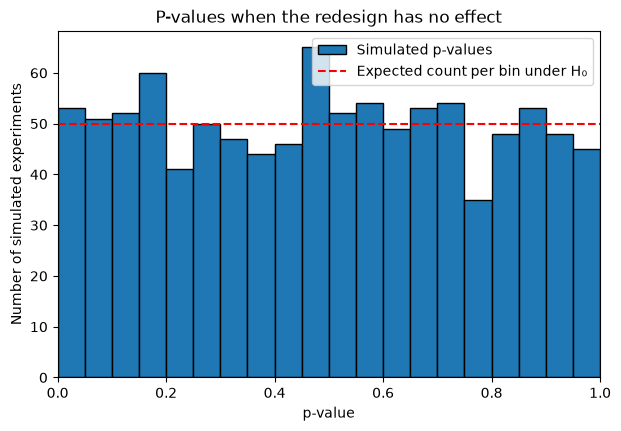

In [23]:
fig, ax = plt.subplots(figsize=(7, 4.5))

plot_p_distribution(
    ax=ax,
    p_values=check,
    title="P-values when the redesign has no effect",
    bars=20,
    n_sims=len(check)
)

plt.show()

In [25]:
def rejection_rate(p_values, alpha=ALPHA):
    """Return the proportion of p-values below `alpha`."""
    # TODO 3: compute the proportion of `p_values` that are less than `alpha`.
    return np.mean(p_values < alpha)

In [26]:
print(rejection_rate(check))

0.053


---
## Section A: Simulating a world where the redesign does nothing
**TODO 1 to 5 · 25 points**

Simulate 100,000 A/B tests in which the true mean engagement time is **100
seconds** (the redesign has no effect whatsoever) at the pilot's sample size of
n = 26. Each simulated test draws 26 users, runs a two-sided one-sample t-test
against 100, and records the p-value.

Then plot the histogram of all 100,000 p-values.

In [ ]:
# TODO 4: simulate `N_SIMS` experiments in which the redesign has NO effect
# (true mean equals the baseline) at the pilot sample size, using SEED_A, then
# report the proportion of p-values below ALPHA.
p_null = ...
false_positive_rate = ...

print(f"Proportion of p < {ALPHA}: {false_positive_rate}")

In [ ]:
# Sanity check (not graded separately): plot the Section A distribution on its
# own, using your plot_p_distribution helper, to confirm the helper works
# before you build the side-by-side figure in Section B.
fig, ax = plt.subplots(figsize=(7, 4.5))
...
plt.show()

### Written answer A *(3-5 sentences)*

> Describe the **shape** of the p-value distribution when H₀ is true. What
> proportion of p-values fell below α = 0.05 in *your* run? What statistical
> concept does that proportion represent, and is the value you got a coincidence
> or a consequence of how the test is built?

**TODO 5: your answer here.**

*[Replace this line with your answer.]*

---
## Section B: Simulating a world where the redesign works
**TODO 6 to 7 · 25 points**

Now simulate 100,000 A/B tests in which the redesign delivers exactly what the
design team promised: true mean = **106 seconds**, SD = 15, n = 26. Plot this
histogram **side by side** with the one from Section A.

In [ ]:
# TODO 6: simulate `N_SIMS` experiments in which the redesign DOES work
# (true mean = M_H1) at the pilot sample size, using SEED_B, and report the
# proportion of simulated A/B tests that reached significance.
p_alt_pilot = ...
power_pilot = ...

print(f"Simulated power at n = {N_PILOT}: {power_pilot}")

In [ ]:
# TODO 7: produce a SIDE-BY-SIDE figure comparing Section A (left) and
# Section B (right), using your plot_p_distribution helper. Give the figure an
# overall title and save it as "figure1_null_vs_alternative.png".
...
plt.show()

### Written answer B *(3-5 sentences)*

> What proportion of the 100,000 simulated A/B tests rejected the null
> hypothesis at α = 0.05? Why did so many simulated tests fail to reach
> significance **even though the +6 second effect was real by construction**?
> Given that, what does the real pilot's p = 0.08 actually license you to
> conclude about the redesign?

*[Replace this line with your answer.]*

---
## Section C: How many users did they actually need?
**TODO 8 to 10 · 25 points**

The industry convention for A/B testing is **80% power**: a test should find a
real effect at least 4 times out of 5.

1. Compute **Cohen's d** for this scenario.
2. Run a power analysis to find the sample size that reaches 80% power at
   α = 0.05, two-sided, and report it as a whole number of users.
3. Re-run the H₁ simulation at that sample size and report the simulated power.
4. Save a side-by-side figure comparing n = 26 with your new n.

**The money.** Each user in an A/B test costs ShopFlow **$1.50** in cloud
logging and marketing spend.

In [ ]:
# TODO 8: compute Cohen's d for this scenario, then run a power analysis to
# find the sample size needed for 80% power at alpha = 0.05, two-sided.
# Report the result as a whole number of users.
effect_size = ...
n_required = ...

print(f"Cohen's d = {effect_size}")
print(f"Users needed for 80% power: {n_required}")

In [ ]:
# TODO 9: re-run the H1 simulation at this new sample size using SEED_C,
# report the simulated power, and save a side-by-side figure comparing n = 26 (left) with
# n = n_required (right) as "figure2_power_comparison.png".
p_alt_powered = ...
power_powered = ...

print(f"Simulated power at n = {n_required}: {power_powered}")

...
plt.show()

In [ ]:
# TODO 10: compute the dollar cost of the underpowered pilot and of the
# adequately powered test, and the difference between them.
cost_pilot = ...
cost_powered = ...

print(f"Pilot cost:         ${cost_pilot}")
print(f"Adequately powered: ${cost_powered}")
print(f"Incremental cost:   ${...}")

### Written answer C *(3-5 sentences)*

> Report both costs and the difference. Describe how the shape of the p-value
> distribution changed between the two sample sizes. Then make the business
> case: is the extra spend worth it?

*[Replace this line with your answer.]*

---
## Section D: Tell the Product Manager
**TODO 11 · 25 points**

Write a **3-4 sentence** recommendation addressed to the Product Manager on
what ShopFlow should do about the redesign. Your recommendation should be
specific and actionable.

Write for a reader with no statistics background. No formulas.

### Your recommendation

**TODO 11: your answer here.**

*[Replace this line with your recommendation.]*

---
## Before you submit

- [ ] `DEBUG_MODE = False`, and `Kernel > Restart & Run All` completed cleanly
- [ ] Notebook saved **with outputs visible**
- [ ] Both figures render in the notebook
- [ ] All four written answers completed
- [ ] External source disclosure filled in at the top
- [ ] Notebook exported to PDF, and the figures and written answers actually
      appear in the PDF
- [ ] Both files submitted: the `.ipynb` and the `.pdf`